# 4. Visualization
Updated charts and data-driven interpretations for `BA_overseas_data.xlsx`. This notebook runs independently of Notebook 03 and uses the same preparation rules. Run all cells from the top.

Place the workbook beside the notebook or in `../data/cleaned/`. Dependencies: pandas, numpy, matplotlib and openpyxl. Each country or industry comparison uses within-group rates; sample sizes are displayed. AI intensity is analyzed separately from the seven binary indicators.


## 4.1 Load data and configure plots


In [8]:
from pathlib import Path
import pandas as pd
import numpy as np

data_path = Path("../data/cleaned/BA_overseas_data.xlsx")
raw_df = pd.read_excel(data_path)
raw_df.columns = raw_df.columns.astype(str).str.strip()
raw_columns = raw_df.columns.tolist()
required_columns = [
    'Job_id', 'Country', 'Job_Title', 'Company_Name', 'Industry', 'Source', 'Job_Url',
    'Date_Posted', 'Date_Collected', 'Salary_Min', 'Salary_Max',
    'Salary_Currency', 'Experience_Min', 'Experience_Max', 'Education',
    'Excel', 'SQL', 'Python', 'R', 'Tableau', 'Power_BI',
    'ai_skill_explicit', 'ai_skill_level', 'JD_text',
]
missing_columns = sorted(set(required_columns) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

# The workbook ends with a total, an empty row, and a coding note.
# These are not vacancies and must never enter a posting denominator.
valid_job = raw_df['Job_id'].astype('string').str.strip().str.fullmatch(r'BA\d+', na=False)
excluded_rows = raw_df.loc[~valid_job].copy()
df = raw_df.loc[valid_job].copy().reset_index(drop=True)
if df.empty:
    raise ValueError('No valid BA job IDs were found.')
df['Job_id'] = df['Job_id'].astype('string').str.strip()
if df['Job_id'].duplicated().any():
    raise ValueError('Duplicate Job_id values found. Review them before analysis.')

for col in ['Country', 'Industry', 'Education', 'Salary_Currency', 'Source']:
    df[col] = df[col].astype('string').str.strip().replace('', pd.NA)
country_map = {
    'united states': 'United States', 'united kingdom': 'United Kingdom',
    'singapore': 'Singapore', 'hong kong': 'Hong Kong', 'canada': 'Canada',
    'australia': 'Australia', 'ireland': 'Ireland',
}
df['Country'] = df['Country'].str.casefold().map(country_map).fillna(df['Country'])
industry_map = {
    'financial services': 'Financial Services', 'technology': 'Technology',
    'industiral': 'Industrial', 'industrial': 'Industrial',
    'education': 'Education', 'other': 'Other', 'unknown': 'Unknown',
}
df['Industry_Clean'] = df['Industry'].str.casefold().map(industry_map).fillna(df['Industry']).fillna('Unknown')
education_map = {
    "bachelor's": "Bachelor's", 'bachelor': "Bachelor's",
    'bachelor’s': "Bachelor's", 'not specified': 'Not Specified',
    'third level degree': 'Third level degree',
}
df['Education_Clean'] = df['Education'].str.casefold().map(education_map).fillna(df['Education']).fillna('Not Specified')

for col in ['Date_Posted', 'Date_Collected']:
    df[col] = pd.to_datetime(df[col], errors='coerce')
for col in ['Experience_Min', 'Experience_Max', 'Salary_Min', 'Salary_Max']:
    df[col + '_num'] = pd.to_numeric(df[col], errors='coerce')
    if df[col + '_num'].lt(0).any():
        raise ValueError(f'Negative values in {col}; review the source.')

# Explicit AI mentions replace the old AI_tools indicator.
# The separate level variable is ordinal and is NOT a binary skill.
skill_columns = ['Excel', 'SQL', 'Python', 'R', 'Tableau', 'Power_BI', 'ai_skill_explicit']
skill_labels = {
    'Excel': 'Excel', 'SQL': 'SQL', 'Python': 'Python', 'R': 'R',
    'Tableau': 'Tableau', 'Power_BI': 'Power BI',
    'ai_skill_explicit': 'AI skills explicitly mentioned',
}
for col in skill_columns:
    values = pd.to_numeric(df[col], errors='coerce')
    bad = df[col].notna() & ~values.isin([0, 1])
    if bad.any():
        raise ValueError(f'{col} must contain 0, 1 or missing values: {df.loc[bad, "Job_id"].tolist()}')
    df[col] = values.astype('Int64')
levels = pd.to_numeric(df['ai_skill_level'], errors='coerce')
if (df['ai_skill_level'].notna() & ~levels.isin([0, 2, 3])).any():
    raise ValueError('AI levels must be 0 = no mention, 2 = preferred, or 3 = required.')
df['ai_skill_level'] = levels.astype('Int64')
ai_level_labels = {0: 'No AI mention', 2: 'AI preferred', 3: 'AI required'}
df['AI_Level_Label'] = df['ai_skill_level'].map(ai_level_labels).astype('string').fillna('Not specified')

# Preserve suspect values for audit. Exclude inverted ranges only from the
# additional salary summary with valid bounds; never guess a corrected salary.
inverted_salary = (df['Salary_Min_num'].notna() & df['Salary_Max_num'].notna()
                   & df['Salary_Min_num'].gt(df['Salary_Max_num']))
df['Salary_Range_Invalid'] = inverted_salary
valid_salary_pair = (df[['Salary_Min_num', 'Salary_Max_num']].notna().all(axis=1)
                     & ~inverted_salary)
df['Salary_Midpoint'] = ((df['Salary_Min_num'] + df['Salary_Max_num']) / 2).where(valid_salary_pair)
df['Number_of_Skills'] = df[skill_columns].sum(axis=1, min_count=len(skill_columns))
ai_comparable = df[['ai_skill_explicit', 'ai_skill_level']].notna().all(axis=1)
ai_inconsistent = ai_comparable & df['ai_skill_explicit'].ne(df['ai_skill_level'].isin([2, 3]).astype(int))

# Flags are for review, not proof that a source value is wrong.
date_after_collection = df['Date_Posted'].gt(df['Date_Collected'])
quality_summary = pd.DataFrame({
    'Check': ['Non-posting rows excluded', 'Duplicate job URLs',
              'Posting date after collection date', 'Minimum salary exceeds maximum',
              'AI explicit and level disagree'],
    'Count': [len(excluded_rows), df['Job_Url'].dropna().duplicated().sum(),
              date_after_collection.sum(), inverted_salary.sum(), ai_inconsistent.sum()],
})

N = len(df)
country_sizes = df['Country'].fillna('Not Specified').value_counts()
country_order = country_sizes.index.tolist()
industry_sizes = df['Industry_Clean'].value_counts()
industry_order = industry_sizes.index.tolist()

def frequency_table(series, label):
    result = series.fillna('Not Specified').value_counts(dropna=False).rename_axis(label).reset_index(name='Job_Postings')
    result['Percentage'] = (result['Job_Postings'] / N * 100).round(1)
    return result

def skill_rates_by(group):
    # Missing indicators are excluded per skill, rather than counted as zero.
    grouping = df[group].fillna('Not Specified')
    return df.groupby(grouping)[skill_columns].mean().mul(100)

print(f'Dataset: {data_path.name}')
print(f'Excel rows: {len(raw_df)}; valid job postings: {N}; excluded non-posting rows: {len(excluded_rows)}')
print(f'Countries: {df["Country"].nunique()}; standardized industries: {df["Industry_Clean"].nunique()}')
print('Collection period:', df['Date_Collected'].min().date(), 'to', df['Date_Collected'].max().date())


Dataset: BA_overseas_data.xlsx
Excel rows: 199; valid job postings: 196; excluded non-posting rows: 3
Countries: 7; standardized industries: 5
Collection period: 2026-09-15 to 2026-10-27


In [9]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 13, 'axes.spines.top': False, 'axes.spines.right': False})

# Return tables as well as charts so values can be checked or reused.
def count_chart(series, title, xlabel='Number of postings'):
    counts = series.fillna('Not Specified').value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(10, max(3.8, .5 * len(counts))))
    bars = ax.barh(counts.index.astype(str), counts.values, color='#28658b')
    ax.bar_label(bars, labels=[f'{n} ({n/N:.1%})' for n in counts.values], padding=4)
    ax.set_xlim(0, max(counts.max() * 1.3, 1)); ax.set_xlabel(xlabel); ax.set_title(title)
    fig.tight_layout(); plt.show()
    return counts

def skill_heatmap(group, order, title):
    rates = skill_rates_by(group).reindex(order)
    sizes = df.groupby(df[group].fillna('Not Specified')).size().reindex(order)
    matrix = rates.T.astype(float)
    fig, ax = plt.subplots(figsize=(max(10, 1.7 * len(order)), 6))
    image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy()), aspect='auto', cmap='Blues', vmin=0, vmax=100)
    ax.set_xticks(range(len(order)), [f'{name}\n(n={int(sizes[name])})' for name in order], rotation=20, ha='right')
    ax.set_yticks(range(len(skill_columns)), [skill_labels[col] for col in skill_columns])
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix.iloc[i, j]
            ax.text(j, i, 'NA' if pd.isna(value) else f'{value:.1f}%', ha='center', va='center', color='white' if pd.notna(value) and value >= 55 else 'black')
    ax.set_title(title); fig.colorbar(image, ax=ax, label='Mentions among available indicators (%)')
    fig.tight_layout(); plt.show()
    return rates

display(quality_summary)


,Check,Count
0,Non-posting rows excluded,3
1,Duplicate job URLs,0
2,Posting date after collection date,51
3,Minimum salary exceeds maximum,1
4,AI explicit and level disagree,0


## 4.2 Job postings by country


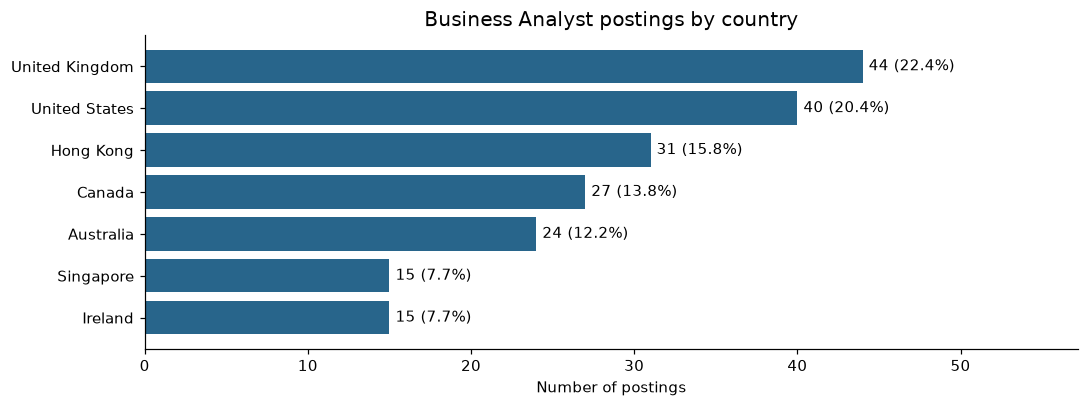

In [10]:
country_counts = count_chart(df['Country'], 'Business Analyst postings by country')


In [11]:
print('The sample contains ' + '; '.join(f'{name}: {n} ({n/N:.1%})' for name, n in country_sizes.items()) + '.')
print('These counts describe sample composition, not the relative size of the labor markets. Skill comparisons below use within-country percentages.')


The sample contains United Kingdom: 44 (22.4%); United States: 40 (20.4%); Hong Kong: 31 (15.8%); Canada: 27 (13.8%); Australia: 24 (12.2%); Singapore: 15 (7.7%); Ireland: 15 (7.7%).
These counts describe sample composition, not the relative size of the labor markets. Skill comparisons below use within-country percentages.


## 4.3 Job postings by industry


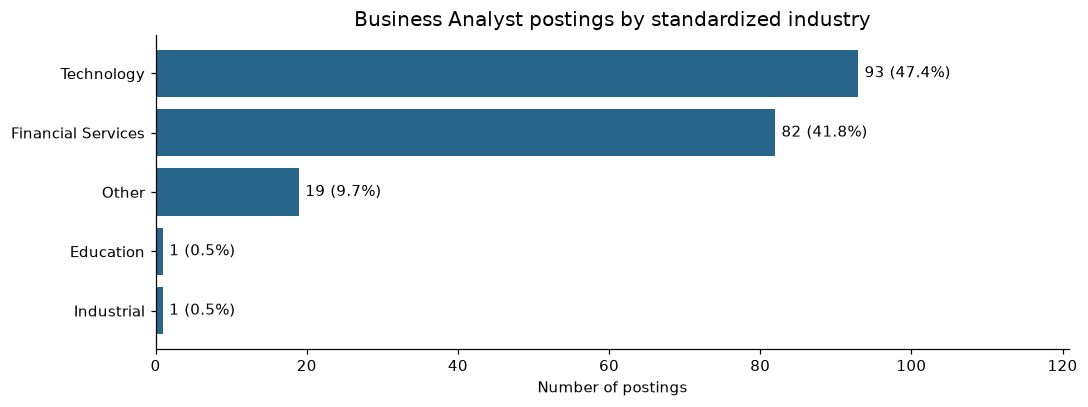

In [12]:
industry_counts = count_chart(df['Industry_Clean'], 'Business Analyst postings by standardized industry')


In [13]:
print('Industry composition: ' + '; '.join(f'{name}: {n} ({n/N:.1%})' for name, n in industry_sizes.items()) + '.')
main_n = df['Industry_Clean'].isin(['Technology', 'Financial Services']).sum()
print(f'Technology and Financial Services together represent {main_n} of {N} postings ({main_n/N:.1%}). '
      'The main industry comparison focuses on these groups; very small categories do not support reliable industry conclusions.')


Industry composition: Technology: 93 (47.4%); Financial Services: 82 (41.8%); Other: 19 (9.7%); Industrial: 1 (0.5%); Education: 1 (0.5%).
Technology and Financial Services together represent 175 of 196 postings (89.3%). The main industry comparison focuses on these groups; very small categories do not support reliable industry conclusions.


## 4.4 Education requirements


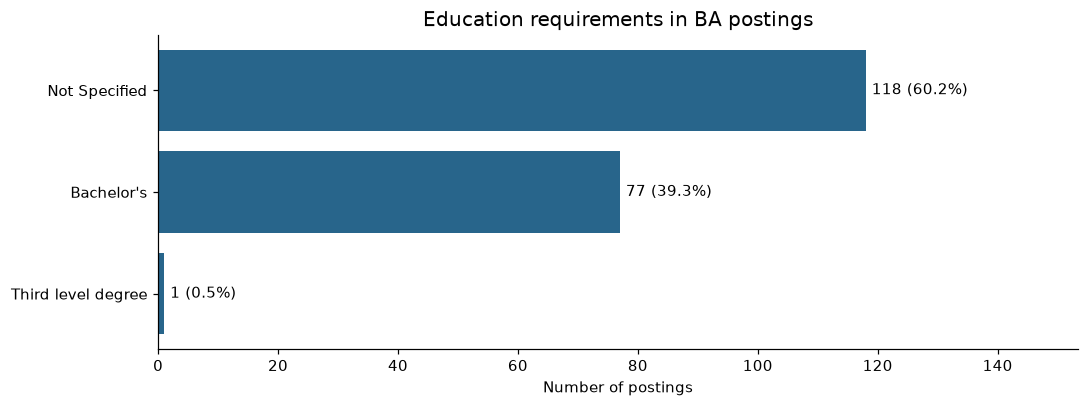

In [14]:
education_counts = count_chart(df['Education_Clean'], 'Education requirements in BA postings')


In [15]:
bachelor_n = df['Education_Clean'].eq("Bachelor's").sum()
unspecified_n = df['Education_Clean'].eq('Not Specified').sum()
print(f'The standardized bachelor category contains {bachelor_n} postings ({bachelor_n/N:.1%}); '
      f'education is unspecified in {unspecified_n} ({unspecified_n/N:.1%}). '
      'An unspecified entry does not establish that no degree is required. Third level degree remains a separate category.')


The standardized bachelor category contains 77 postings (39.3%); education is unspecified in 118 (60.2%). An unspecified entry does not establish that no degree is required. Third level degree remains a separate category.


## 4.5 Distribution of minimum required experience


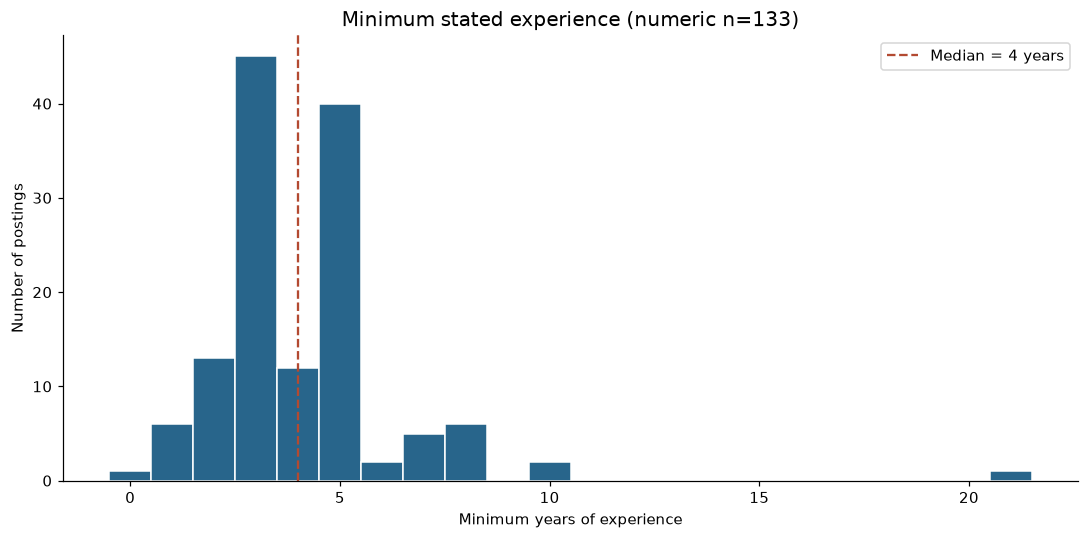

In [16]:
experience_data = df['Experience_Min_num'].dropna()
fig, ax = plt.subplots(figsize=(10, 5))
if experience_data.empty:
    ax.text(.5, .5, 'No numeric experience observations', ha='center', transform=ax.transAxes)
else:
    bins = np.arange(np.floor(experience_data.min()) - .5, np.ceil(experience_data.max()) + 1.5, 1)
    ax.hist(experience_data, bins=bins, color='#28658b', edgecolor='white')
    ax.axvline(experience_data.median(), color='#b34a31', linestyle='--', label=f'Median = {experience_data.median():g} years')
    ax.legend()
ax.set_title(f'Minimum stated experience (numeric n={len(experience_data)})')
ax.set_xlabel('Minimum years of experience'); ax.set_ylabel('Number of postings')
fig.tight_layout(); plt.show()


In [17]:
print(f'Numeric minimum experience is available in {len(experience_data)} of {N} postings; '
      f'{N-len(experience_data)} have no parseable value.')
if not experience_data.empty:
    q1, median, q3 = experience_data.quantile([.25, .5, .75])
    print(f'The mean is {experience_data.mean():.2f} years and median {median:g}; '
          f'the middle half lies between {q1:g} and {q3:g} years. '
          f'The observed range is {experience_data.min():g} to {experience_data.max():g} years.')
print('Missing experience is not counted as zero, and extreme coded values should be verified against the source.')


Numeric minimum experience is available in 133 of 196 postings; 63 have no parseable value.
The mean is 4.14 years and median 4; the middle half lies between 3 and 5 years. The observed range is 0 to 21 years.
Missing experience is not counted as zero, and extreme coded values should be verified against the source.


## 4.6 Technical skill mentions
AI is measured by `ai_skill_explicit`. The ordinal AI level is excluded from binary skill counts.


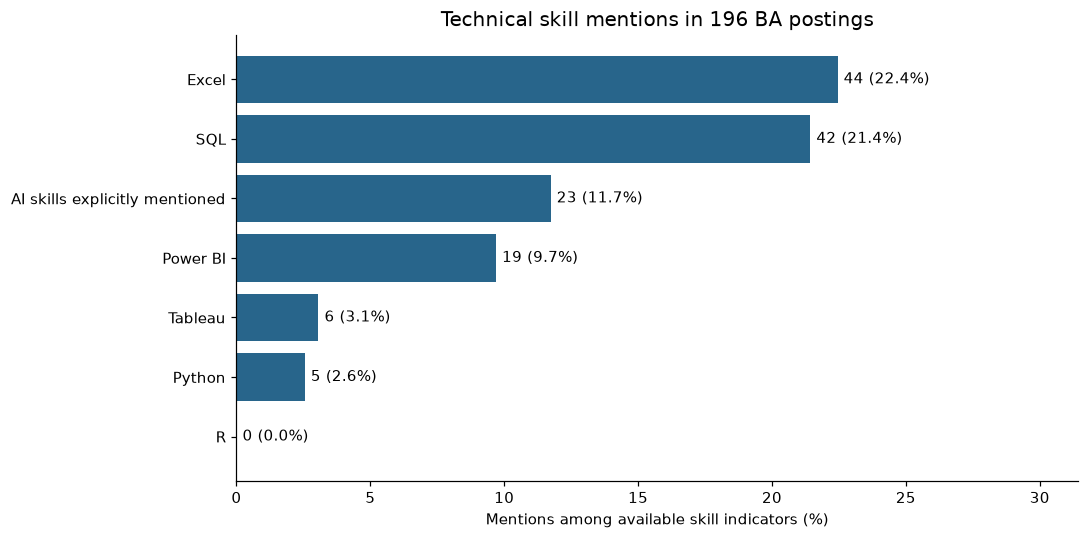

,Mentions,Available,Percentage
Excel,44,196,22.4
SQL,42,196,21.4
ai_skill_explicit,23,196,11.7
Power_BI,19,196,9.7
Tableau,6,196,3.1
Python,5,196,2.6
R,0,196,0.0


In [18]:
skill_counts = df[skill_columns].sum().astype(int).sort_values(ascending=False, kind='stable')
skill_available = df[skill_columns].notna().sum()
skill_percentages = skill_counts / skill_available.reindex(skill_counts.index).replace(0, np.nan) * 100
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(skill_counts))
bars = ax.barh(y, skill_percentages.fillna(0).values, color='#28658b')
ax.set_yticks(y, [skill_labels[col] for col in skill_counts.index]); ax.invert_yaxis()
ax.bar_label(bars, labels=[f'{skill_counts[col]} ({skill_percentages[col]:.1f}%)' if pd.notna(skill_percentages[col]) else 'NA' for col in skill_counts.index], padding=4)
ax.set_xlim(0, max(10, skill_percentages.max() * 1.4)); ax.set_xlabel('Mentions among available skill indicators (%)')
ax.set_title(f'Technical skill mentions in {N} BA postings');fig.tight_layout();plt.show()
display(pd.DataFrame({'Mentions':skill_counts, 'Available':skill_available, 'Percentage':skill_percentages}).reindex(skill_counts.index).round(1))


In [19]:
print('Recorded skill mentions: ' + '; '.join(f'{skill_labels[col]}: {skill_counts[col]} ({skill_percentages[col]:.1f}%)' for col in skill_counts.index) + '.')
print('These percentages measure coded mentions. An absent mention is not proof that a skill is unnecessary, and the AI indicator does not identify a specific AI product.')


Recorded skill mentions: Excel: 44 (22.4%); SQL: 42 (21.4%); AI skills explicitly mentioned: 23 (11.7%); Power BI: 19 (9.7%); Tableau: 6 (3.1%); Python: 5 (2.6%); R: 0 (0.0%).
These percentages measure coded mentions. An absent mention is not proof that a skill is unnecessary, and the AI indicator does not identify a specific AI product.


## 4.7 Technical skill mentions by country


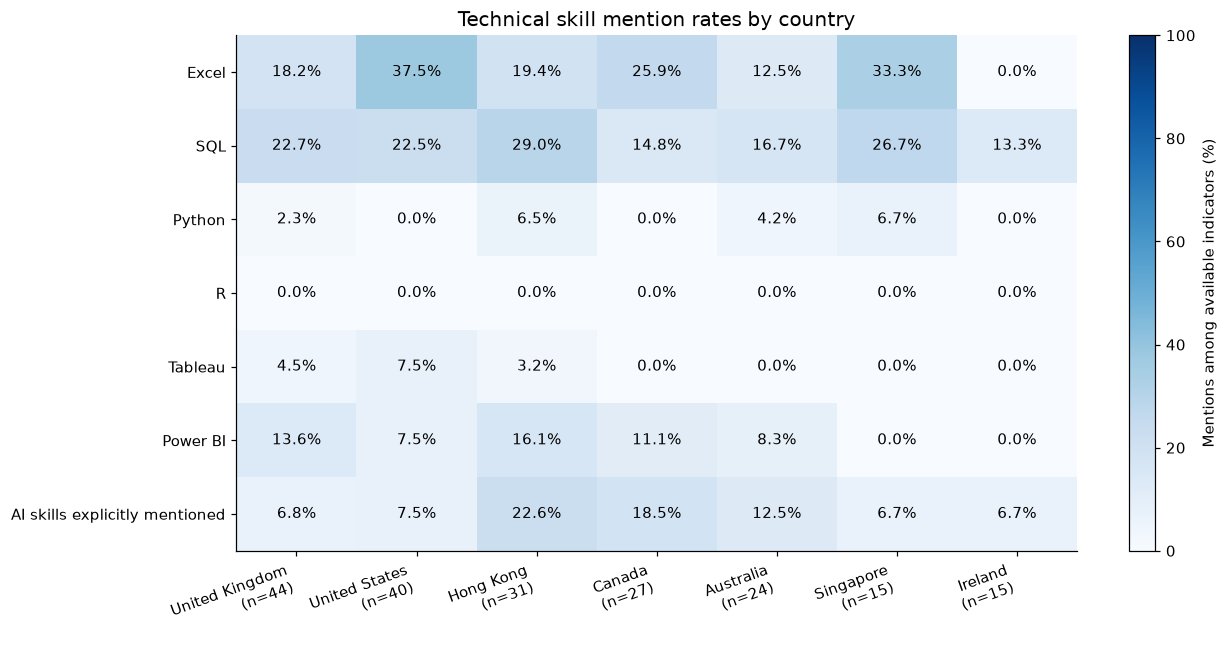

,Excel,SQL,Python,R,Tableau,Power_BI,ai_skill_explicit
Country,,,,,,,
United Kingdom,18.2,22.7,2.3,0.0,4.5,13.6,6.8
United States,37.5,22.5,0.0,0.0,7.5,7.5,7.5
Hong Kong,19.4,29.0,6.5,0.0,3.2,16.1,22.6
Canada,25.9,14.8,0.0,0.0,0.0,11.1,18.5
Australia,12.5,16.7,4.2,0.0,0.0,8.3,12.5
Singapore,33.3,26.7,6.7,0.0,0.0,0.0,6.7
Ireland,0.0,13.3,0.0,0.0,0.0,0.0,6.7


In [20]:
skill_by_country = skill_heatmap('Country', country_order, 'Technical skill mention rates by country')
display(skill_by_country.round(1))


In [21]:
for col in ['Excel', 'SQL', 'Power_BI', 'ai_skill_explicit']:
    values = skill_by_country[col].dropna()
    if not values.empty:
        leaders = ', '.join(values.index[values.eq(values.max())])
        print(f'{skill_labels[col]}: highest observed rate in {leaders} ({values.max():.1f}%).')
print('Percentages adjust the denominator for sample size, but do not control for country differences in industry mix or seniority. Small differences may reflect only a few postings.')


Excel: highest observed rate in United States (37.5%).
SQL: highest observed rate in Hong Kong (29.0%).
Power BI: highest observed rate in Hong Kong (16.1%).
AI skills explicitly mentioned: highest observed rate in Hong Kong (22.6%).
Percentages adjust the denominator for sample size, but do not control for country differences in industry mix or seniority. Small differences may reflect only a few postings.


## 4.8 Technical skill mentions by industry
The heatmap focuses on Technology and Financial Services. The full table retains other industries with their sample sizes; one-posting categories are not treated as industry estimates.


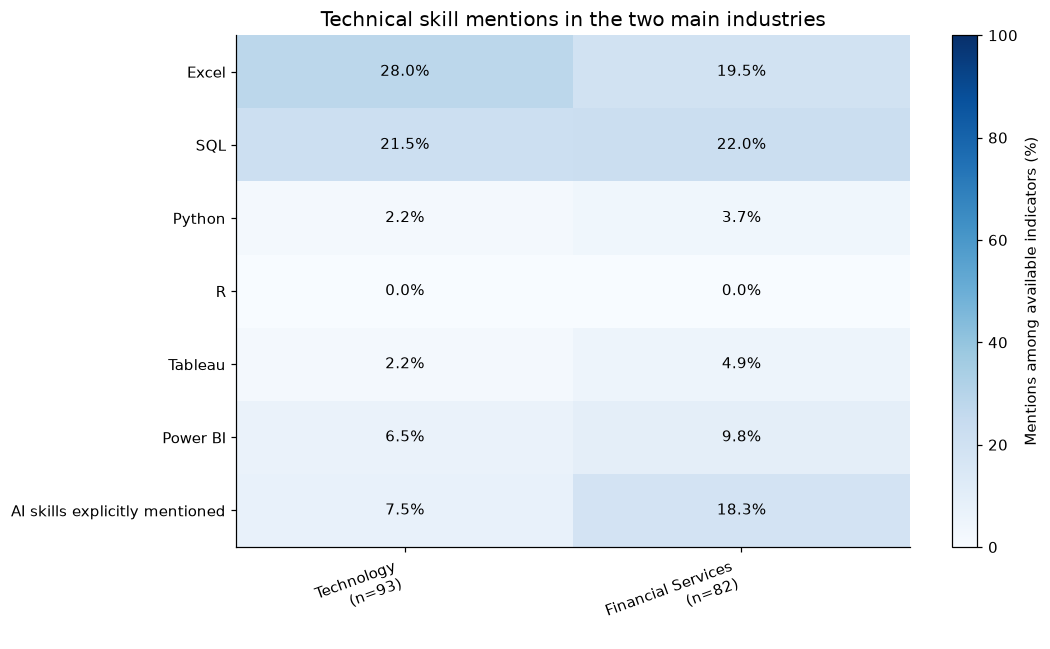

,Job_Postings,Excel,SQL,Python,R,Tableau,Power_BI,ai_skill_explicit
Industry_Clean,,,,,,,,
Technology,93,28.0,21.5,2.2,0.0,2.2,6.5,7.5
Financial Services,82,19.5,22.0,3.7,0.0,4.9,9.8,18.3
Other,19,10.5,21.1,0.0,0.0,0.0,21.1,0.0
Industrial,1,0.0,0.0,0.0,0.0,0.0,100.0,100.0
Education,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [22]:
skill_by_industry_all = skill_rates_by('Industry_Clean')
industry_comparison = [name for name in ['Technology', 'Financial Services'] if name in industry_sizes.index]
skill_by_industry = skill_heatmap('Industry_Clean', industry_comparison, 'Technical skill mentions in the two main industries')
display(industry_sizes.to_frame('Job_Postings').join(skill_by_industry_all).round(1))


In [23]:
if set(['Technology', 'Financial Services']).issubset(skill_by_industry.index):
    for col in ['Excel', 'SQL', 'Power_BI', 'Tableau', 'ai_skill_explicit']:
        t = skill_by_industry.loc['Technology', col]
        f = skill_by_industry.loc['Financial Services', col]
        print(f'{skill_labels[col]}: Technology {t:.1f}%; Financial Services {f:.1f}%; '
              f'Technology minus Financial Services = {t-f:+.1f} percentage points.')
print('The comparisons are descriptive and unadjusted; no statistical significance or causal effect is inferred.')


Excel: Technology 28.0%; Financial Services 19.5%; Technology minus Financial Services = +8.4 percentage points.
SQL: Technology 21.5%; Financial Services 22.0%; Technology minus Financial Services = -0.4 percentage points.
Power BI: Technology 6.5%; Financial Services 9.8%; Technology minus Financial Services = -3.3 percentage points.
Tableau: Technology 2.2%; Financial Services 4.9%; Technology minus Financial Services = -2.7 percentage points.
AI skills explicitly mentioned: Technology 7.5%; Financial Services 18.3%; Technology minus Financial Services = -10.8 percentage points.
The comparisons are descriptive and unadjusted; no statistical significance or causal effect is inferred.


## 4.9 Number of identified technical skills per posting
Only the seven binary indicators are added. If any skill indicator is missing, the total is missing rather than an incomplete sum.


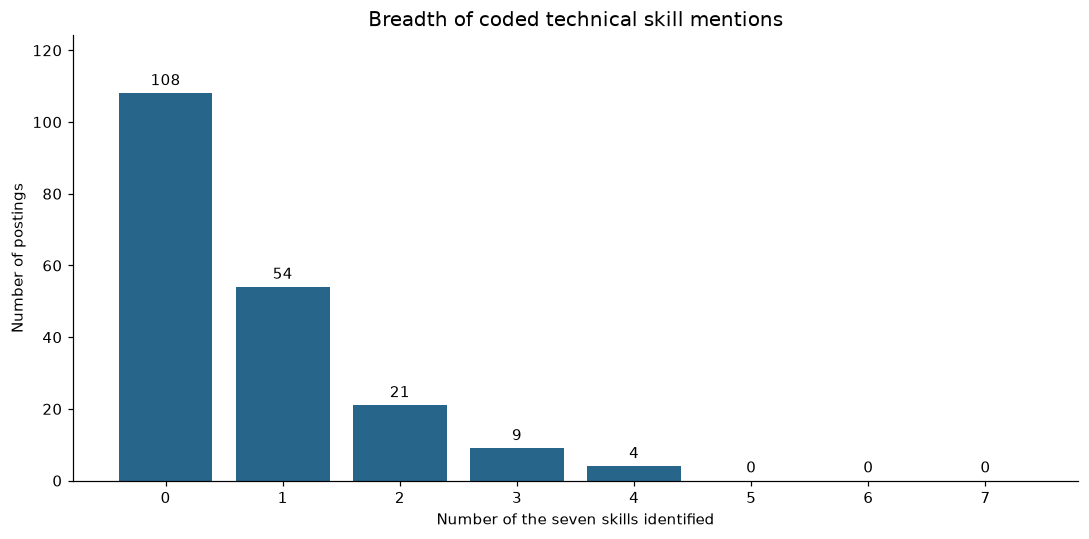

In [24]:
skill_number_counts = df['Number_of_Skills'].dropna().astype(int).value_counts().reindex(range(len(skill_columns)+1), fill_value=0).sort_index()
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(skill_number_counts.index, skill_number_counts.values, color='#28658b')
ax.bar_label(bars, padding=3);ax.set_xticks(range(len(skill_columns)+1));ax.set_ylim(0, max(1, skill_number_counts.max()*1.15))
ax.set_xlabel('Number of the seven skills identified');ax.set_ylabel('Number of postings')
ax.set_title('Breadth of coded technical skill mentions');fig.tight_layout();plt.show()


In [25]:
complete_n = df['Number_of_Skills'].notna().sum()
print(f'Complete skill indicators: {complete_n}/{N} postings. '
      f'Mean number of identified skills: {df["Number_of_Skills"].mean():.2f}.')
print('Distribution: ' + '; '.join(f'{k} skills: {n} postings' for k,n in skill_number_counts.items()) + '.')
print('Zero identifies no mentions among the seven coded tools, not an absence of all technical requirements.')


Complete skill indicators: 196/196 postings. Mean number of identified skills: 0.71.
Distribution: 0 skills: 108 postings; 1 skills: 54 postings; 2 skills: 21 postings; 3 skills: 9 postings; 4 skills: 4 postings; 5 skills: 0 postings; 6 skills: 0 postings; 7 skills: 0 postings.
Zero identifies no mentions among the seven coded tools, not an absence of all technical requirements.


## 4.10 Technical skill mentions across countries
This grouped bar chart uses the same rates as Section 4.7.


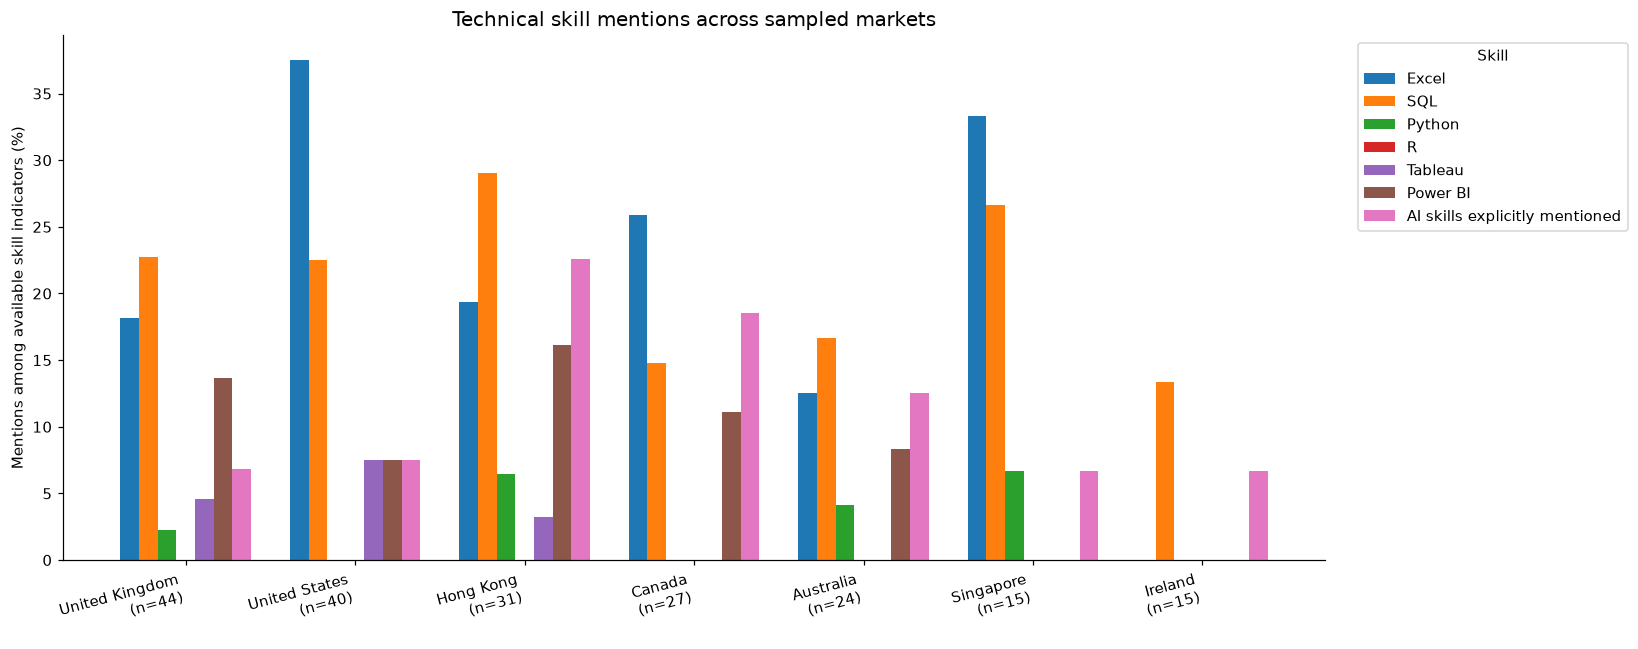

In [26]:
skill_country_pct = skill_by_country.reindex(country_order)
x = np.arange(len(country_order));width = .11
fig, ax = plt.subplots(figsize=(15, 6))
for i, col in enumerate(skill_columns):
    ax.bar(x + (i-(len(skill_columns)-1)/2)*width, skill_country_pct[col].astype(float), width, label=skill_labels[col])
ax.set_xticks(x, [f'{name}\n(n={country_sizes[name]})' for name in country_order], rotation=15, ha='right')
ax.set_ylabel('Mentions among available skill indicators (%)');ax.set_title('Technical skill mentions across sampled markets')
ax.legend(title='Skill', bbox_to_anchor=(1.02, 1), loc='upper left');fig.tight_layout();plt.show()


## 4.11 AI requirement intensity
The workbook defines level 0 as no mention, level 2 as preferred, and level 3 as required. Counts and within-country percentages describe these categories without averaging the level codes.


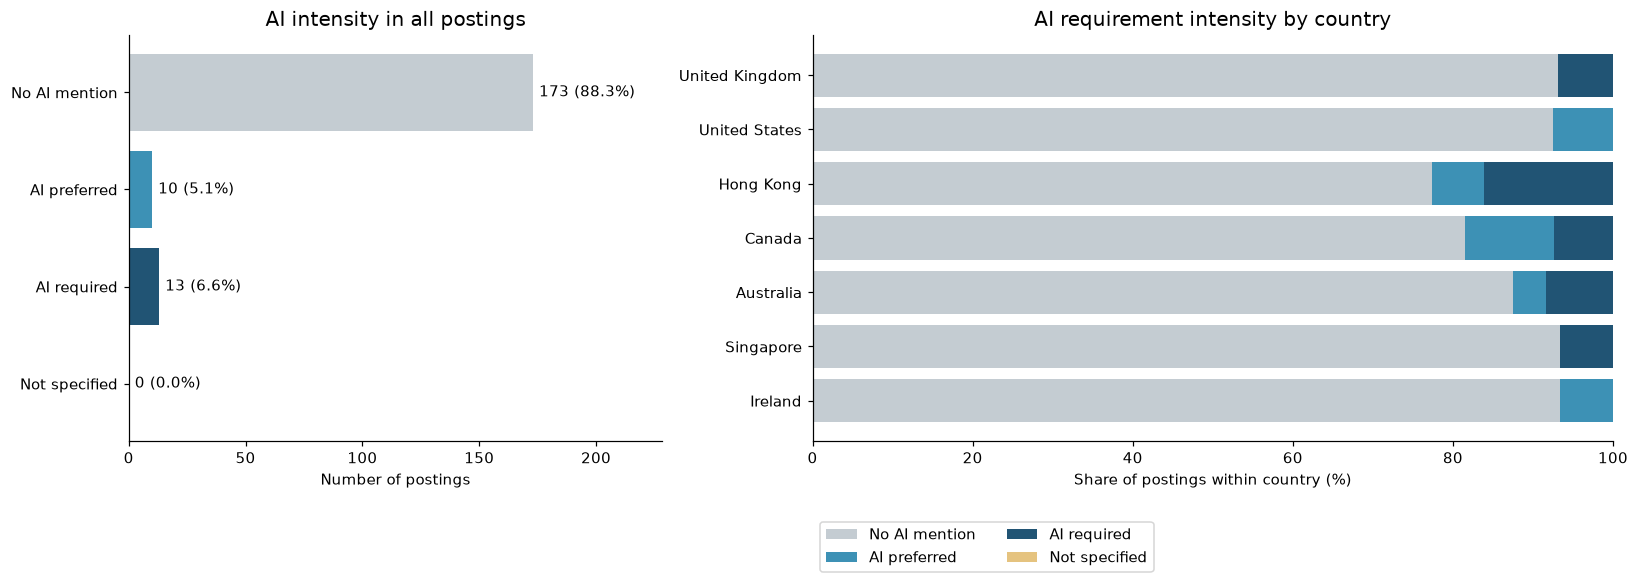

AI_Level_Label,No AI mention,AI preferred,AI required,Not specified
Country,,,,
United Kingdom,41,0,3,0
United States,37,3,0,0
Hong Kong,24,2,5,0
Canada,22,3,2,0
Australia,21,1,2,0
Singapore,14,0,1,0
Ireland,14,1,0,0


AI_Level_Label,No AI mention,AI preferred,AI required,Not specified
Country,,,,
United Kingdom,93.2,0.0,6.8,0.0
United States,92.5,7.5,0.0,0.0
Hong Kong,77.4,6.5,16.1,0.0
Canada,81.5,11.1,7.4,0.0
Australia,87.5,4.2,8.3,0.0
Singapore,93.3,0.0,6.7,0.0
Ireland,93.3,6.7,0.0,0.0


In [27]:
ai_order = ['No AI mention', 'AI preferred', 'AI required', 'Not specified']
ai_counts = df['AI_Level_Label'].value_counts().reindex(ai_order, fill_value=0)
ai_country_counts = pd.crosstab(df['Country'].fillna('Not Specified'), df['AI_Level_Label']).reindex(index=country_order, columns=ai_order, fill_value=0)
ai_country_pct = ai_country_counts.div(ai_country_counts.sum(axis=1), axis=0).mul(100)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios':[1, 1.5]})
colors = ['#c4ccd2', '#3d91b5', '#215474', '#e5c37f']
bars = axes[0].barh(ai_order, ai_counts.values, color=colors);axes[0].invert_yaxis()
axes[0].bar_label(bars, labels=[f'{n} ({n/N:.1%})' for n in ai_counts.values], padding=4)
axes[0].set_xlim(0,max(1,ai_counts.max()*1.32));axes[0].set_title('AI intensity in all postings');axes[0].set_xlabel('Number of postings')
left = np.zeros(len(ai_country_pct))
for label,color in zip(ai_order,colors):
    vals = ai_country_pct[label].to_numpy(dtype=float)
    axes[1].barh(country_order, vals, left=left, color=color, label=label);left+=vals
axes[1].invert_yaxis();axes[1].set_xlim(0,100);axes[1].set_xlabel('Share of postings within country (%)');axes[1].set_title('AI requirement intensity by country')
axes[1].legend(bbox_to_anchor=(0, -.18), loc='upper left', ncol=2);fig.tight_layout();plt.show()
display(ai_country_counts)
display(ai_country_pct.round(1))


In [28]:
ai_n = int(df['ai_skill_explicit'].eq(1).sum());preferred = int(df['ai_skill_level'].eq(2).sum());required = int(df['ai_skill_level'].eq(3).sum())
print(f'Explicit AI requirements occur in {ai_n}/{N} postings ({ai_n/N:.1%}); '
      f'{preferred} are preferred and {required} are required.')
if ai_n:
    print(f'Among explicit AI mentions, preferred accounts for {preferred/ai_n:.1%} and required for {required/ai_n:.1%}.')
print('A single cross-sectional sample cannot show whether AI requirements are increasing over time.')


Explicit AI requirements occur in 23/196 postings (11.7%); 10 are preferred and 13 are required.
Among explicit AI mentions, preferred accounts for 43.5% and required for 56.5%.
A single cross-sectional sample cannot show whether AI requirements are increasing over time.


## 4.12 Visualization summary and limitations


In [29]:
print(f'The updated figures cover {N} postings, {df["Country"].nunique()} markets and '
      f'{df["Industry_Clean"].nunique()} standardized industries. '
      f'Collection dates range from {df["Date_Collected"].min():%Y-%m-%d} to {df["Date_Collected"].max():%Y-%m-%d}.')
print('Main recorded skills, in descending order: ' + ', '.join(skill_labels[col] for col in skill_counts.index) + '.')
print('All observations come from: ' + ', '.join(df['Source'].dropna().unique()) + '.')
print(f'Quality flags include {int(date_after_collection.sum())} posting dates after collection dates, '
      f'{int(inverted_salary.sum())} inverted salary ranges and {int(ai_inconsistent.sum())} AI coding inconsistencies. '
      'Dates and salary values are retained for review; the source workbook is unchanged.')
print('Market and industry samples are uneven. Tool rates describe coded mentions, not actual hiring decisions or proficiency. '
      'Collection dates differ across observations, so these data are not a balanced longitudinal comparison. '
      'Salary figures use different currencies and may require pay-period verification. '
      'The original four-market pilot brief and any previous findings document need a separate update before they can describe this expanded sample.')


The updated figures cover 196 postings, 7 markets and 5 standardized industries. Collection dates range from 2026-09-15 to 2026-10-27.
Main recorded skills, in descending order: Excel, SQL, AI skills explicitly mentioned, Power BI, Tableau, Python, R.
All observations come from: LinkedIn.
Quality flags include 51 posting dates after collection dates, 1 inverted salary ranges and 0 AI coding inconsistencies. Dates and salary values are retained for review; the source workbook is unchanged.
Market and industry samples are uneven. Tool rates describe coded mentions, not actual hiring decisions or proficiency. Collection dates differ across observations, so these data are not a balanced longitudinal comparison. Salary figures use different currencies and may require pay-period verification. The original four-market pilot brief and any previous findings document need a separate update before they can describe this expanded sample.
